# Supervised models

Notebook 02 showed that the data are a collection of studies, and that the usual random cross-validation partly
measures how well a model recognises a study. This notebook starts with the question that decides how to read every
later score: **how much does a model beat a trivial predictor on a study it has never seen, and is it the same for
every study?** Only then does it compare models.

Protocols, always on identical folds (`src.evaluation`): `random` (shuffled, stratified), `grouped` (5 folds of whole
studies) and `loso` (one study held out at a time, studies with at least 20 rows). Two scores are reported:
**R2**, which compares with the mean of the *test* fold (a value nobody knows beforehand), and **skill**
= 1 - SSE(model) / SSE(mean of the training fold), which is exactly 0 for a model that predicts the training mean
and positive when it does better.

## 0. Setup

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge

warnings.filterwarnings("ignore")
PROJECT_ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                    if (p / "src" / "config.py").exists())
sys.path.insert(0, str(PROJECT_ROOT))

from src.baselines import baseline_models
from src.cleaning import clean_dataframe
from src.config import FIGURES_DIR, RESULTS_DIR, SCALED_CLIP, TARGETS
from src.evaluation import ALL_PROTOCOLS, ModelSpec, compare_models, per_study_scores, summarize, make_folds
from src.loading import load_raw
from src.models import GroupTunedRidge
from src.preprocessing import build_preprocessor, feature_spec

FIG = FIGURES_DIR / "supervised_models"
FIG.mkdir(parents=True, exist_ok=True)
OUT = RESULTS_DIR / "supervised_models"
OUT.mkdir(parents=True, exist_ok=True)

clean = clean_dataframe(load_raw())
print(clean.shape, "| studies held out one at a time:", len(make_folds(clean, "loso")))

(1652, 60) | studies held out one at a time: 15


## 1. Baselines and per-study scores

### 1.1 Reference scores under the three protocols

Two baselines (`src.baselines`): the **global mean** of the training fold, and the **study mean** (the mean of the
same study seen in training; on a study that was held out it can only fall back to the global mean). Two models: a
random forest and a ridge regression, the latter in two versions: the first one as it was before a defect was found
(scaled features unbounded, fixed penalty, see 1.4) and the corrected one (features clipped, penalty chosen by cross-validation
over whole studies inside the training data).

In [2]:
models = baseline_models() + [
    ModelSpec("ridge, no clip (before the fix)", "linear", lambda: Ridge(alpha=1.0), clip=None),
    ModelSpec("ridge, clipped, penalty tuned by study CV", "linear", GroupTunedRidge, uses_source=True),
    ModelSpec("random forest", "tree", lambda: RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1)),
]
results = compare_models(clean, models, protocols=ALL_PROTOCOLS)
results.to_csv(OUT / "03_baselines_folds.csv", index=False)
summary = summarize(results)
summary.to_csv(OUT / "03_baselines_summary.csv", index=False)

order = [m.name for m in models]
for metric in ("skill_mean", "r2_mean"):
    table = summary.pivot_table(index=["target", "model"], columns="protocol", values=metric)
    table = table[["random", "grouped", "loso"]].reindex(order, level="model")
    print(f"\n{metric} (mean over folds; loso = mean over held-out studies)")
    print(table.round(2).to_string())


skill_mean (mean over folds; loso = mean over held-out studies)
protocol                                                         random  grouped  loso
target                model                                                           
charpy_toughness_j    global_mean                                  0.00     0.00  0.00
                      study_mean                                   0.20     0.00  0.00
                      ridge, no clip (before the fix)              0.60    -0.62 -2.46
                      ridge, clipped, penalty tuned by study CV    0.54    -0.22 -0.02
                      random forest                                0.83     0.16  0.22
elongation_pct        global_mean                                  0.00     0.00  0.00
                      study_mean                                   0.30     0.00  0.00
                      ridge, no clip (before the fix)              0.66    -0.44 -1.47
                      ridge, clipped, penalty tuned by study CV  

**Your conclusions:**

- **R2 on an unseen study mostly measures the study's offset.** The training-mean predictor, which learns nothing, scores R2 = -0.37 on yield strength and UTS, -0.68 on elongation, -0.70 on reduction of area and -0.65 on Charpy toughness in the grouped protocol, and down to -2.8 for the ductility targets when one study is held out. A forest at R2 = 0.05 on yield strength is therefore well above the trivial predictor. (My earlier reading of the smoke test, "R2 close to 0 means almost nothing is explained on a new study", was wrong: it had no reference point.)
- **Against the training mean, the forest has a modest but real skill on unseen studies**: yield strength 0.28 (grouped) / 0.30 (leave-one-study-out), UTS 0.42 / 0.39, Charpy toughness 0.16 / 0.22, reduction of area 0.29 / 0.09, elongation 0.28 / -0.06. Strength is the most predictable; elongation is not reliably better than the mean once a single study is held out.
- **The random protocol is far more flattering**: the forest's skill is 0.74-0.86 there, against 0.16-0.42 on unseen studies.
- **The ridge, before the fix, is worse than the mean on unseen studies** (skill between -0.62 and -2.46 on yield strength, UTS and Charpy depending on the protocol): this came from the preprocessing, see 1.4.
- **After the fix (features clipped, penalty chosen by cross-validation over studies inside the training data), the ridge is about as good as the mean**: yield strength 0.02 (grouped) / 0.01 (leave-one-study-out), UTS 0.34 / 0.15, Charpy -0.22 / -0.02, elongation -0.01 / -0.38, reduction of area 0.48 / -0.23. In leave-one-study-out it stays below the forest on every target. The grouped score for reduction of area (0.48, above the forest's 0.29) against -0.23 when studies are held out one at a time shows how much the 5-fold grouped protocol depends on which studies share a fold.


### 1.2 How much of the random score is only the study?

In [3]:
random_skill = summary[summary["protocol"] == "random"].pivot_table(index="target", columns="model", values="skill_mean")
share = pd.DataFrame({
    "study_mean": random_skill["study_mean"],
    "random_forest": random_skill["random forest"],
    "share_of_forest_skill_%": (100 * random_skill["study_mean"] / random_skill["random forest"]).round(0),
}).round(2)
share.to_csv(OUT / "03_study_share_of_random_skill.csv")
print("random protocol, skill:")
print(share.to_string())

random protocol, skill:
                       study_mean  random_forest  share_of_forest_skill_%
target                                                                   
charpy_toughness_j           0.20           0.83                     25.0
elongation_pct               0.30           0.74                     40.0
reduction_of_area_pct        0.55           0.74                     74.0
uts_mpa                      0.35           0.86                     41.0
yield_strength_mpa           0.35           0.82                     43.0


**Your conclusions:**

- **Knowing only the study already gives a large part of the random score**: the study-mean predictor has a skill of 0.35 on yield strength and UTS, 0.30 on elongation, 0.55 on reduction of area and 0.20 on Charpy toughness.
- **As a share of the forest's random skill** that is 43% (yield strength), 41% (UTS), 40% (elongation), 74% (reduction of area) and 25% (Charpy). For reduction of area, the random score mostly says "which study"; for the others it is under half. The rest of the forest's random skill (0.74-0.86) comes from rows of the same study that look alike, including the replicated inputs measured in notebook 02.
- **Consequence**: random-protocol scores should not be the headline; the study-held-out scores are the ones that carry information about a new study.

### 1.3 One score per held-out study

Each study is held out in turn, the model is trained on all the others and scored on it. `skill` is the error
reduction against the training mean, `bias` the mean error (a wrong *level* for the study) and `within_rho` the
Spearman correlation between prediction and truth inside the study (does the model follow the variations of a
study it has never seen, whatever its error on the level?).

rows scored per study and target:
target       yield_strength_mpa  uts_mpa  elongation_pct  reduction_of_area_pct  charpy_toughness_j
study                                                                                              
Cunh                         32       32              31                     32                   0
Evans                       331      331             330                    331                 437
EvansLetter                  52       52              51                     52                 104
Gar&K                        66       40              62                     61                   0
KocakPREv                    21       21              21                     21                   0
Mart                          0        0               0                      0                  63
Pat                           0        0               0                      0                  63
RR82011                      45       46              46          

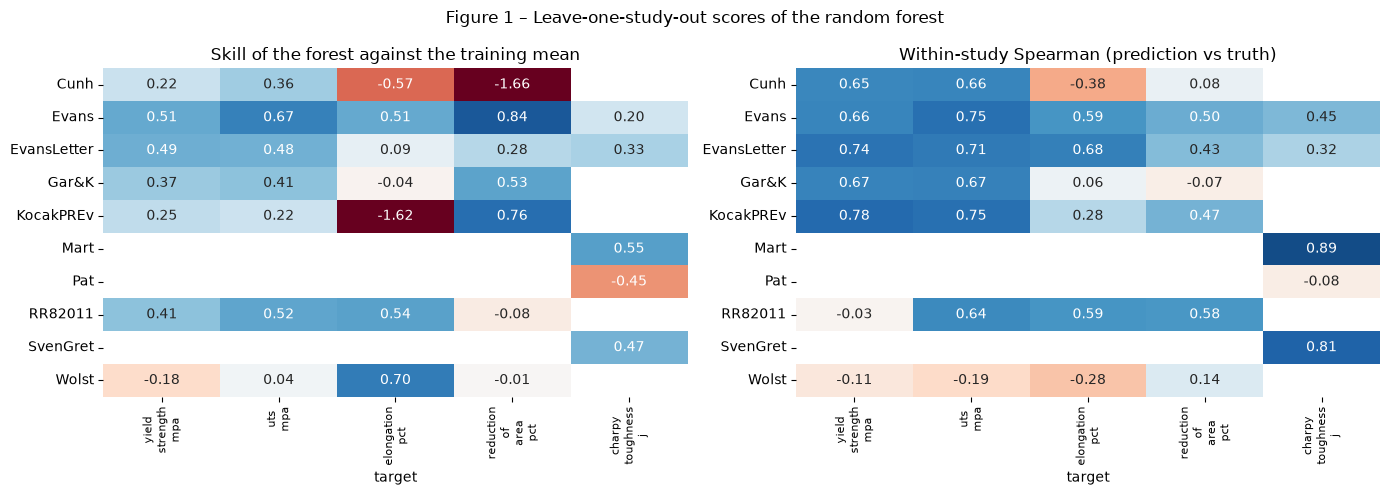

In [4]:
per_study = per_study_scores(results)
per_study.to_csv(OUT / "03_loso_scores.csv", index=False)
forest = per_study[per_study["model"] == "random forest"]
mean_model = per_study[per_study["model"] == "global_mean"]

skill = forest.pivot(index="study", columns="target", values="skill")[TARGETS]
rho = forest.pivot(index="study", columns="target", values="within_rho")[TARGETS]
n_rows = forest.pivot(index="study", columns="target", values="n_test")[TARGETS]
print("rows scored per study and target:")
print(n_rows.fillna(0).astype(int).to_string())
print("\nstudies where the forest beats the training mean (skill > 0), per target:")
print(((skill > 0).sum().astype(str) + " of " + skill.notna().sum().astype(str)).to_string())

bias = pd.DataFrame({"|bias| forest": forest.groupby("target")["bias"].apply(lambda s: s.abs().mean()),
                     "|bias| training mean": mean_model.groupby("target")["bias"].apply(lambda s: s.abs().mean())}).round(1)
print("\nmean |bias| over held-out studies:")
print(bias.loc[TARGETS].to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(skill, annot=True, fmt=".2f", cmap="RdBu", center=0, vmin=-1, vmax=1, ax=axes[0], cbar=False)
axes[0].set_title("Skill of the forest against the training mean")
sns.heatmap(rho, annot=True, fmt=".2f", cmap="RdBu", center=0, vmin=-1, vmax=1, ax=axes[1], cbar=False)
axes[1].set_title("Within-study Spearman (prediction vs truth)")
for ax in axes:
    ax.set_xticklabels([t.replace("_", "\n") for t in TARGETS], fontsize=8)
    ax.set_ylabel("")
fig.suptitle("Figure 1 \u2013 Leave-one-study-out scores of the random forest")
plt.tight_layout()
fig.savefig(FIG / "fig01_loso_skill_and_within_rho.png", dpi=150)
plt.show()

**Your conclusions:**

- **Strength transfers to unseen studies.** The forest beats the training mean on 6 of 7 studies for yield strength (skill 0.22-0.51; only Wolst, -0.18) and on 7 of 7 for UTS (0.04-0.67). Its mean level error is also smaller than that of the training mean: |bias| 25 vs 37 MPa (yield strength) and 26 vs 40 MPa (UTS).
- **It follows the variations inside a study it has never seen**: the within-study Spearman is 0.65-0.78 in five of the seven studies for yield strength and 0.64-0.75 in six of seven for UTS (medians 0.66 and 0.67). The failures are `Wolst` (-0.11 / -0.19; 23 rows) and `RR82011` on yield strength only (-0.03, while its UTS is 0.64).
- **Ductility is less reliable.** Elongation beats the mean in 4 of 7 studies (`Cunh` -0.57, `KocakPREv` -1.62, `Gar&K` -0.04 do not) with a median within-study Spearman of 0.28; reduction of area also in 4 of 7 (`Cunh` -1.66) with a median of 0.43. Part of the negative values comes from studies with a narrow spread (elongation in `KocakPREv` has a standard deviation of 1.8), where the training mean is already close and any error looks large.
- **Charpy toughness**: 4 of 5 studies positive (`Mart` 0.55, `SvenGret` 0.47, `EvansLetter` 0.33, `Evans` 0.20), `Pat` -0.45 (within-study Spearman -0.08). Only five studies, and the test temperature is a feature.
- **`Evans` (42% of the rows) is well predicted on every target** (0.51, 0.67, 0.51, 0.84, 0.20), so any average weighted by rows is dominated by it; this per-study table weights every study equally.
- **Caveats**: studies of 21-32 rows give noisy scores; the explanation of why `Wolst` or `Cunh` fail is not established and they should be inspected before any conclusion about measurement protocols.

### 1.4 Why the first ridge was worse than the mean

In [5]:
spec = feature_spec(clean, "yield_strength_mpa")
X, y = clean[spec.columns], clean["yield_strength_mpa"]
labeled = y.notna().to_numpy()
studies = sorted(clean["source"].value_counts()[lambda s: s >= 20].index)
rows = []
for study, (train, test) in zip(studies, make_folds(clean, "loso")):
    train, test = train[labeled[train]], test[labeled[test]]
    if len(test) < 20:
        continue
    pre = build_preprocessor("linear", spec, clip=None).fit(X.iloc[train])      # as before the fix
    held_out = pre.transform(X.iloc[test]).abs().max().sort_values(ascending=False)
    rows.append({"held-out study": study, "largest |scaled value| in training": round(pre.transform(X.iloc[train]).abs().max().max()),
                 "largest on the held-out study": round(held_out.iloc[0]), "column": held_out.index[0]})
print(f"Without the clip (the bound is now {SCALED_CLIP:g}):")
print(pd.DataFrame(rows).to_string(index=False))

linear = per_study[per_study["model"].str.startswith("ridge")]
effect = linear.groupby(["target", "model"])["skill"].agg(mean_skill="mean", share_positive=lambda s: (s > 0).mean()).round(2)
print("\nleave-one-study-out skill of the two ridge versions:")
print(effect.to_string())

Without the clip (the bound is now 5):
held-out study  largest |scaled value| in training  largest on the held-out study           column
          Cunh                                 995                            195      nb_conc_ppm
         Evans                                 170                            119       cr_conc_wt
   EvansLetter                                 950                             48      nb_conc_ppm
         Gar&K                                1198                            608        v_conc_wt
     KocakPREv                                1162                            162      ti_conc_ppm
       RR82011                                 960                            100 interpass_temp_c
         Wolst                                 860                            100 interpass_temp_c

leave-one-study-out skill of the two ridge versions:
                                                                 mean_skill  share_positive
target                m

**Your conclusions:**

- **The scaled features reached hundreds or thousands.** `RobustScaler` divides by the interquartile range of the median-filled column. For variables that are missing in more than half the rows (Nb, Sb, Cr) or concentrated on one value (interpass temperature, 64% of rows at 200 C) that range is zero, scikit-learn then divides by 1, and the variable stays in its raw unit. The largest scaled value was 170-1198 on the training rows and still 48-608 on a held-out study (V in `Gar&K` 608, Nb in `Cunh` 195, Ti in `KocakPREv` 162, Cr in `Evans` 119). A ridge extrapolates wildly on such values.
- **Fix applied in `src`**: the linear preprocessor clips the scaled numeric features to [-5, 5] (`SCALED_CLIP`), and `GroupTunedRidge` chooses the penalty among 1, 10, 100 and 1000 by cross-validation over whole studies of the training rows, so the scored study never takes part in the choice.
- **Leave-one-study-out skill, before -> after**: yield strength -1.69 -> +0.01, UTS -0.69 -> +0.15, elongation -1.47 -> -0.38, reduction of area -1.62 -> -0.23, Charpy -2.46 -> -0.02. The defect is gone (the ridge no longer extrapolates wildly), but a linear model brings little on a new study: about the mean for yield strength and Charpy, a modest gain for UTS, still below the mean for the ductility targets.
- **On the earlier figure**: a manual search over four settings on the scored studies gave +0.09 on yield strength; with the penalty chosen inside the training data it is +0.01. The first number was optimistic, as flagged at the time.
- **Tested but not adopted**: filling by scaling first then using 0, and dropping the poorly reported variables to avoid any NaN. The first gives no gain; the second hurts yield strength and UTS (the alloy elements carry the transferable signal) and helps only reduction of area and Charpy on 4 studies.


## 2. Ablations of the feature set

Before comparing a zoo of models, the feature set is fixed once, on two reference models (random forest, study-tuned ridge),
by changing one thing at a time against the baseline of section 1 (plan: `doc/04_ablation_plan.md`, code: `src/ablation.py`).

**Decision rule** (agreed): a variant is paired with the baseline on each held-out study (leave-one-study-out). It **helps** if its
mean skill gain is at least 0.05 and it wins on at least 2/3 of the (target, study) pairs, it **hurts** symmetrically, otherwise it is a **tie**.
The four tensile targets are pooled (27 pairs); Charpy toughness is read on its own (5 studies). The pair (`Cunh`, reduction of area) is left out:
its skill has a tiny denominator (notebook 03 diagnosis, `EXCLUDED_FROM_JUDGMENT`). The `grouped` protocol, repeated on 5 seeds, and `random` are context, never a ranking.

mean skill gain against the baseline, leave-one-study-out (share of pairs won); rule: gain >= 0.05, wins >= 67%
algo                   random forest                            ridge                   
scope             charpy_toughness_j       tensile charpy_toughness_j            tensile
variant                                                                                 
no_missing_flags        -0.00  (40%)  +0.00  (48%)       -0.01  (60%)       -0.07  (41%)
no_censored_flags       -0.00  (60%)  +0.01  (63%)       -0.01  (20%)       -0.00  (74%)
no_flags                +0.00  (40%)  +0.01  (67%)       -0.05  (60%)       -0.05  (41%)
drop_mo                 +0.04  (20%)  -0.02  (37%)       -0.00  (40%)       -0.04  (30%)
drop_arc                -0.00  (40%)  -0.03  (37%)       +0.01  (60%)  +0.06 helps (81%)
study_weights           +0.07  (60%)  -0.00  (44%)  -0.20 hurts (20%)       -0.04  (44%)
pca6                    +0.07  (40%)  -0.00  (41%)       -0.00  (40%)       -0.01  (41%

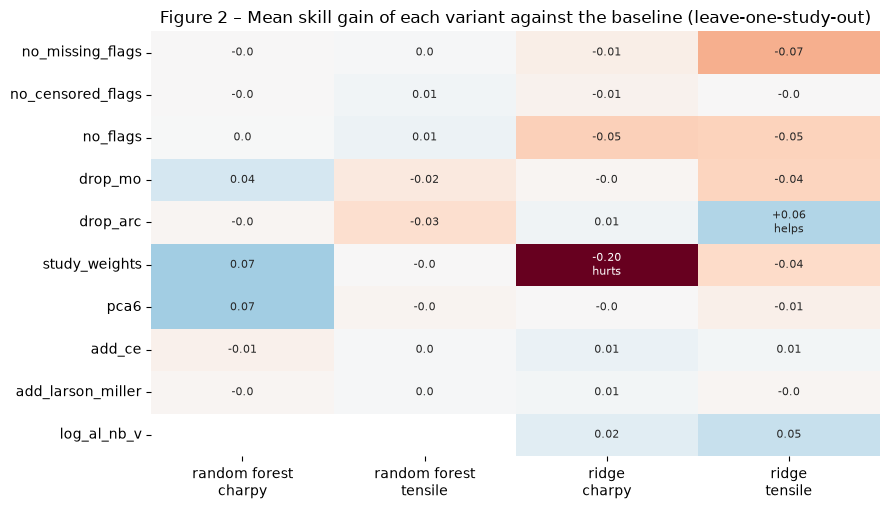

In [6]:
from src.ablation import VARIANTS, decision_table, grouped_seed_spread, loso_deltas, run_ablation
from src.config import MIN_SKILL_GAIN, MIN_WIN_SHARE

ablation = run_ablation(clean)                      # about 7 minutes
ablation.to_csv(OUT / "03_ablation_folds.csv", index=False)
decisions = decision_table(ablation)
decisions.to_csv(OUT / "03_ablation_decisions.csv", index=False)

order = [v for v in VARIANTS if v != "baseline"]
columns = ["algo", "scope"]
gain = decisions.pivot_table(index="variant", columns=columns, values="mean_skill_gain").reindex(order)
verdict = decisions.pivot_table(index="variant", columns=columns, values="verdict", aggfunc="first").reindex(order)
wins = decisions.pivot_table(index="variant", columns=columns, values="win_share").reindex(order)
shown = gain.round(2).map(lambda v: "" if pd.isna(v) else f"{v:+.2f}") + " " + verdict.fillna("").replace("tie", "") + \
        wins.map(lambda v: "" if pd.isna(v) else f" ({v:.0%})")
print(f"mean skill gain against the baseline, leave-one-study-out (share of pairs won); rule: gain >= {MIN_SKILL_GAIN}, wins >= {MIN_WIN_SHARE:.0%}")
print(shown.to_string())
print("\nverdicts:", decisions["verdict"].value_counts().to_dict(), "out of", len(decisions), "comparisons")

fig, ax = plt.subplots(figsize=(9, 5.2))
flat = gain.copy(); flat.columns = [f"{a}\n{s.replace('_toughness_j', '')}" for a, s in flat.columns]
labels = flat.round(2).astype(str)
for (a, s) in gain.columns:
    name = f"{a}\n{s.replace('_toughness_j', '')}"
    for v in order:
        if verdict.loc[v, (a, s)] in ("helps", "hurts"):
            labels.loc[v, name] = f"{gain.loc[v, (a, s)]:+.2f}\n{verdict.loc[v, (a, s)]}"
sns.heatmap(flat, annot=labels, fmt="", cmap="RdBu", center=0, vmin=-0.2, vmax=0.2, cbar=False, ax=ax, annot_kws={"fontsize": 8})
ax.set_ylabel(""); ax.set_xlabel("")
ax.set_title("Figure 2 \u2013 Mean skill gain of each variant against the baseline (leave-one-study-out)")
plt.tight_layout(); fig.savefig(FIG / "fig02_ablation_skill_gain.png", dpi=150); plt.show()

**Your conclusions:**

- **36 of the 38 comparisons are ties; none helps the forest.** The only two verdicts: the ridge **without current, voltage and heat input** helps on the tensile targets (+0.06, 81% of the pairs won), and the ridge **with study weights** hurts Charpy toughness (-0.20, 20% won: `EvansLetter` -0.48, `Mart` -0.37). With 38 comparisons at this threshold, one "helps" can come by chance (2.3 below).
- **The ties are expected, not a failure of the rule.** The skill of the 5-fold grouped protocol moves by 0.03-0.16 from one seed to the next (UTS 0.16, Charpy 0.12): a gain of 0.05 is the size of the noise, which is why the rule asks for wins on two thirds of the studies as well.
- **Nothing that adds information helps.** PCA scores (-0.00 forest, -0.01 ridge on the tensile targets), carbon equivalent (+0.00 / +0.01), Larson-Miller parameter (+0.00 / -0.00) and the shifted log on Al, Nb, V for the ridge (+0.05, but only 52% of the pairs won) are ties. Two caveats: the carbon equivalent exists on only 418 rows (25%) because a missing element is not zero, and the Larson-Miller parameter adds nothing a tree cannot already get from the PWHT temperature and time.
- **Study weights do not help a new study**: no effect on the tensile targets (-0.00 forest, -0.04 ridge) and a clear loss for the ridge on Charpy toughness.


### 2.1 Do the missing / censored flags help on a study already seen, and not on a new one?

In [7]:
flags = decisions[decisions["variant"].isin(["no_missing_flags", "no_censored_flags", "no_flags"]) & (decisions["scope"] == "tensile")]
table = flags.set_index(["algo", "variant"])[["gain_random", "gain_grouped", "mean_skill_gain", "win_share"]]
table.columns = ["random", "grouped", "leave-one-study-out", "share won (loso)"]
print("skill change when the flags are REMOVED, four tensile targets pooled:")
print(table.round(2).to_string())

skill change when the flags are REMOVED, four tensile targets pooled:
                                 random  grouped  leave-one-study-out  share won (loso)
algo          variant                                                                  
random forest no_missing_flags     0.00     0.00                 0.00              0.48
              no_censored_flags    0.00     0.00                 0.01              0.63
              no_flags             0.00     0.00                 0.01              0.67
ridge         no_missing_flags    -0.03    -0.04                -0.07              0.41
              no_censored_flags   -0.00    -0.01                -0.00              0.74
              no_flags            -0.02    -0.04                -0.05              0.41


**Your conclusions:**

- **The idea that the flags are study fingerprints that help a seen study and not a new one is not supported.** For the forest, removing the missing and censored flags changes the skill by 0.00-0.01 under every protocol: a tree keeps the NaN and can split on them, so the flags say nothing it cannot read already.
- **For the ridge, the missing flags carry real information** that the median fill erases: removing them costs 0.03 (random), 0.04 (grouped) and 0.07 (leave-one-study-out). The loss is *larger* on a new study than on a seen one, which is the opposite of study recognition. The verdict is still a tie, because removing them wins on 41% of the pairs and the loss is not spread over two thirds of them. The censored flags change nothing (|gain| <= 0.01).


### 2.2 Molybdenum, study by study

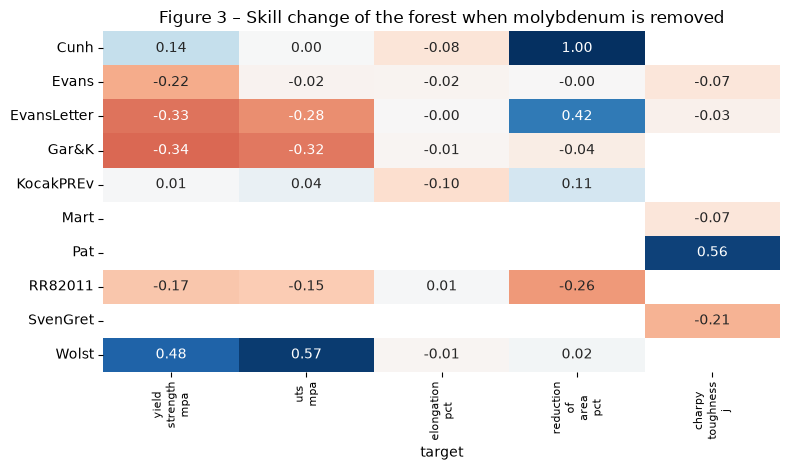

studies x targets that improve / get worse without Mo: 12 / 21


In [8]:
delta_mo = loso_deltas(ablation, "random forest", "drop_mo")
fig, ax = plt.subplots(figsize=(8, 4.8))
sns.heatmap(delta_mo, annot=True, fmt=".2f", cmap="RdBu", center=0, vmin=-0.6, vmax=0.6, cbar=False, ax=ax)
ax.set_xticklabels([t.replace("_", "\n") for t in delta_mo.columns], fontsize=8); ax.set_ylabel("")
ax.set_title("Figure 3 \u2013 Skill change of the forest when molybdenum is removed")
plt.tight_layout(); fig.savefig(FIG / "fig03_drop_mo_per_study.png", dpi=150); plt.show()
print("studies x targets that improve / get worse without Mo:", int((delta_mo > 0).sum().sum()), "/", int((delta_mo < 0).sum().sum()))

**Your conclusions:**

- **The diagnosis of the failures is confirmed, and it is not a fix.** Without Mo, `Wolst` improves a lot (UTS +0.57, yield strength +0.48), as does `Pat` on Charpy (+0.56) and `Cunh` on reduction of area (+1.00, a pair left out of the rule). But 21 of the 33 study-target pairs get worse: `Evans` yield strength -0.22, `EvansLetter` -0.33 (yield) and -0.28 (UTS), `Gar&K` -0.34 and -0.32, `RR82011` -0.17, `SvenGret` Charpy -0.21.
- **Reading**: Mo is a real strengthening signal in the alloyed studies where it varies inside the range seen in training, and misleading on a study whose Mo is out of that range or whose relation has the opposite sign (`Wolst`, `Pat`). Pooled, the effect is a tie on the tensile targets (-0.02, 37% of the pairs won) and on Charpy (+0.04 on average but won on one study of five, `Pat`). Mo stays in; any recommendation involving Mo has to be checked study by study.
- **The diagnosis itself** (done by a helper agent on scikit-learn 1.5, scripts outside the repository, not reproduced here) is summarised in `doc/03_project_structure.md`.


### 2.3 Arc variables, and how much of a gain is noise

In [9]:
spread = grouped_seed_spread(ablation)
print("baseline, 5-fold grouped protocol repeated on 5 seeds: mean and standard deviation over seeds of the skill")
print(spread.round(2).to_string())

tensile = ["yield_strength_mpa", "uts_mpa", "elongation_pct", "reduction_of_area_pct"]
part = ablation[(ablation["protocol"] == "grouped") & (ablation["algo"] == "ridge") & ablation["variant"].isin(["baseline", "drop_arc"])
                & ablation["target"].isin(tensile)]
per_seed = part.groupby(["variant", "seed"])["skill"].mean().unstack("variant")
per_seed["gain"] = per_seed["drop_arc"] - per_seed["baseline"]
print("\nridge without current / voltage / heat input, grouped protocol, tensile targets, per seed:")
print(per_seed.round(3).to_string())
print("\nleave-one-study-out, ridge, skill change without the arc variables:")
print(loso_deltas(ablation, "ridge", "drop_arc").round(2).to_string())

baseline, 5-fold grouped protocol repeated on 5 seeds: mean and standard deviation over seeds of the skill
                                     skill_mean  skill_std
algo          target                                      
random forest charpy_toughness_j           0.01       0.12
              elongation_pct               0.33       0.03
              reduction_of_area_pct        0.22       0.08
              uts_mpa                      0.29       0.16
              yield_strength_mpa           0.31       0.05
ridge         charpy_toughness_j          -0.15       0.15
              elongation_pct               0.02       0.10
              reduction_of_area_pct        0.38       0.12
              uts_mpa                      0.26       0.14
              yield_strength_mpa           0.06       0.08

ridge without current / voltage / heat input, grouped protocol, tensile targets, per seed:
variant  baseline  drop_arc   gain
seed                              
0           0.208     0

**Your conclusions:**

- **Noise floor**: the standard deviation over seeds of the baseline skill is, for the forest, 0.03-0.05 for yield strength and elongation, 0.08 for reduction of area, 0.12-0.16 for UTS and Charpy; for the ridge, 0.08-0.15. Differences below these values between two grouped scores say nothing.
- **Arc variables and the ridge**: removing them gains +0.06 in leave-one-study-out, with small gains in most studies (`Evans` +0.01 to +0.05 on three tensile targets but -0.10 on reduction of area and -0.12 on Charpy, `Gar&K` +0.01 to +0.08, `RR82011`, `Wolst`) and large swings on two small ones (`Cunh` UTS +0.52, `KocakPREv` UTS +0.43 but yield strength -0.34). In the grouped protocol the gain is +0.09, +0.06, -0.06, +0.01, +0.05 over the five seeds (mean +0.03, positive in four). It is coherent with these variables being study identifiers (89-98% study, notebook 02) that a linear model uses as offsets, but the evidence is modest. For the forest the effect is -0.03 (a tie), so it is **not** applied to the common feature set; it stays an option to test on the other linear models of the zoo.


### 2.4 What is kept

**The feature set of the zoo is the baseline** (`doc/01`): the 25 numeric features, the three categoricals, the `_missing` and `_censored` flags, no PCA scores, no derived feature, no study weights, Mo and arc variables kept.

| Variant | Verdict | Decision |
|---|---|---|
| flags (missing, censored, both) | tie (forest 0.00-0.01); ridge loses 0.05-0.07 without the missing flags | keep |
| `drop_mo` | tie, mechanism of the failures confirmed | keep Mo, read it study by study |
| `drop_arc` | helps the ridge (+0.06), tie for the forest (-0.03) | keep in the common set; **option for the linear models of the zoo** |
| `study_weights` | hurts the ridge on Charpy, tie elsewhere | not applied |
| `pca6`, `add_ce`, `add_larson_miller`, `log_al_nb_v` | ties | not applied |

**A change to the written plan, to be agreed**: `doc/04_ablation_plan.md` said that a tie keeps the simpler setting (the variant that removes something). Applied here it would remove the missing flags (forest tie), Mo and the arc variables, against the evidence above. The proposal: **a tie keeps the baseline**, and only a verdict "helps" changes the feature set.


## 3. Next sections

To do, in this order:

1. a model zoo (Lasso, k-NN, SVR, histogram gradient boosting, MLP) with hyperparameters tuned **inside the training fold** by cross-validation over studies; families routed by NaN support (k-NN, SVR, MLP and Lasso on the `linear` family, boosting with native NaN handling); `drop_arc` tested as an option for the linear models;
2. Charpy toughness reformulated once the "fixed energy" reading of 514 of its 879 values is checked in the source papers (`doc/03_project_structure.md`), with a sensitivity row without those values;
3. the four tensile properties modeled jointly on their 650 complete rows, against four separate models;
4. the `grouped_weld` protocol as a diagnostic on the retained models;
5. feature importance, with the within-study coefficient of notebook 02 as the reference for plausibility.
